In [ ]:
from google.colab import files
import cv2
from google.colab.patches import cv2_imshow
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
arquivo = files.upload()

Saving 400x400.png to 400x400 (1).png


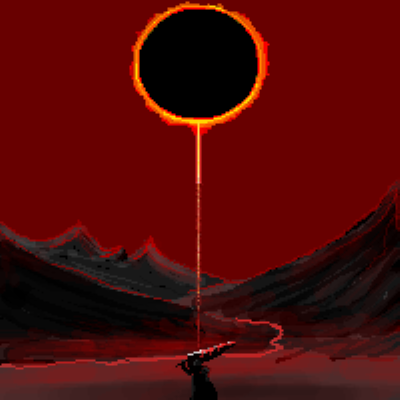

array([[[  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104],
        ...,
        [  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104]],

       [[  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104],
        ...,
        [  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104]],

       [[  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104],
        ...,
        [  0,   0, 104],
        [  0,   0, 104],
        [  0,   0, 104]],

       ...,

       [[ 43,  43,  80],
        [ 43,  43,  80],
        [ 43,  43,  80],
        ...,
        [ 40,  40,  61],
        [ 40,  40,  61],
        [ 40,  40,  61]],

       [[ 43,  43,  80],
        [ 43,  43,  80],
        [ 43,  43,  80],
        ...,
        [ 41,  41,  57],
        [ 41,  41,  57],
        [ 41,  41,  57]],

       [[ 43,  43,  80],
        [ 43,  43,  80],
        [ 43,  43,  80],
        ...,
        [ 41,  41,  57],
        [ 41,  41,  57],
        [ 41,  41,  57]]], dtype=uint8)
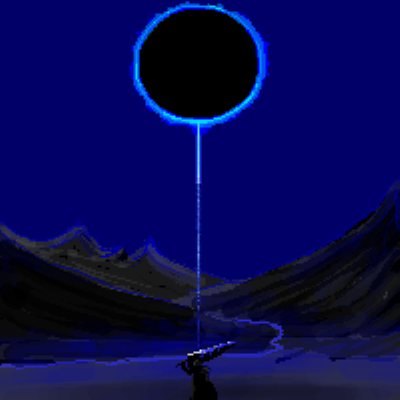

In [ ]:
img = cv2.imread('400x400.png')
cv2_imshow(img)
img

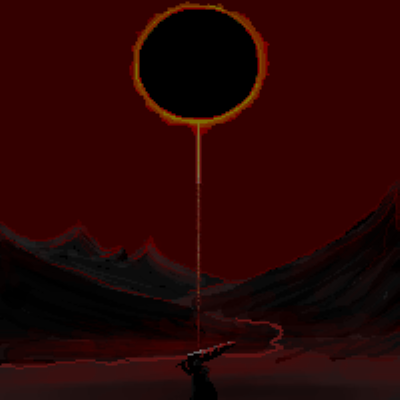

In [ ]:
cv2_imshow(img/2)


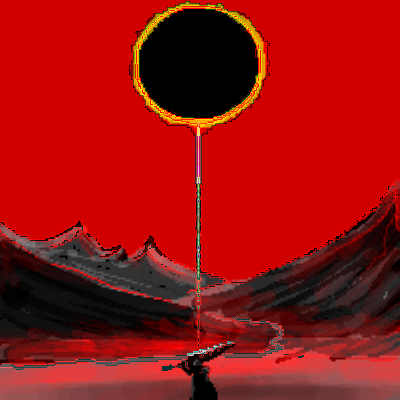

In [ ]:
cv2_imshow(img * 2)

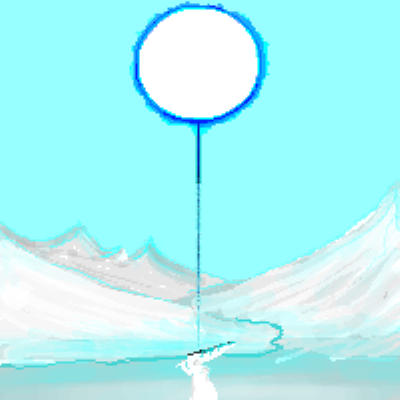

In [ ]:
cv2_imshow(255 - img)

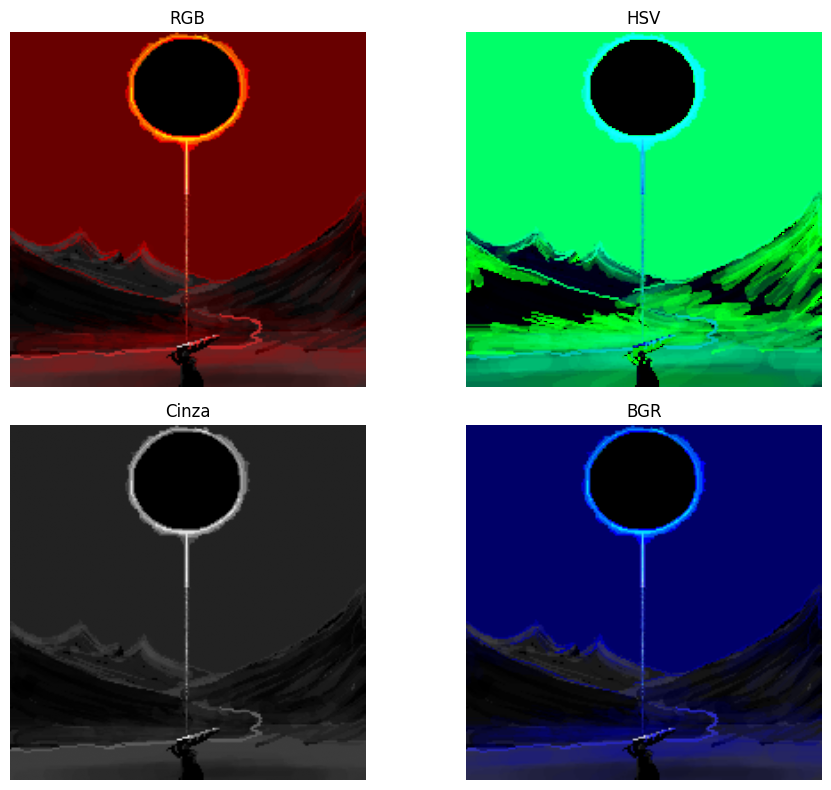

In [ ]:
# Criação das variantes
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
img_grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Configuração da plotagem
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0, 0].imshow(img_rgb)
ax[0, 0].set_title('RGB')
ax[0, 0].axis('off')

ax[0, 1].imshow(img_hsv)
ax[0, 1].set_title('HSV')
ax[0, 1].axis('off')

ax[1, 0].imshow(img_grey, cmap='gray')
ax[1, 0].set_title('Cinza')
ax[1, 0].axis('off')

ax[1, 1].imshow(img)
ax[1, 1].set_title('BGR')
ax[1, 1].axis('off')

plt.tight_layout()
plt.savefig('imagens.png')
plt.show()

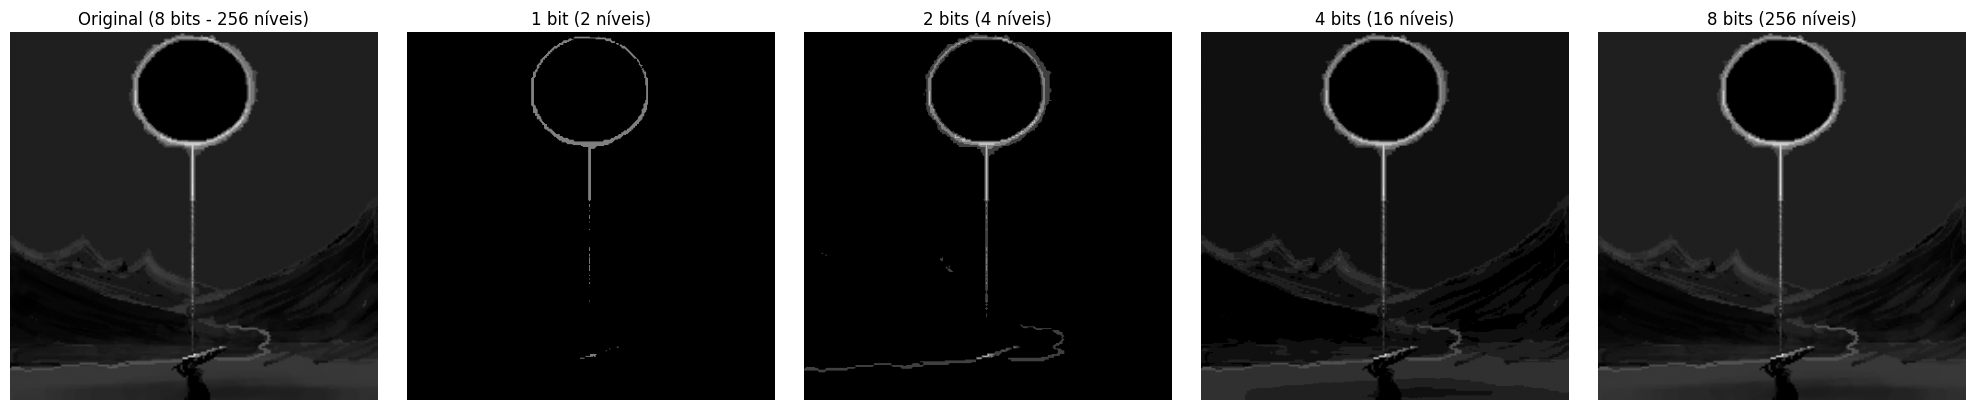

In [ ]:
# Quantização da imagem em tons de cinza
def quantizar(imagem, bits):
    niveis = 2 ** bits
    intervalo = 256 // niveis
    return (imagem // intervalo) * intervalo

img_1bit = quantizar(img_grey, 1)
img_2bit = quantizar(img_grey, 2)
img_4bit = quantizar(img_grey, 4)
img_8bit = quantizar(img_grey, 8)

# Configuração da plotagem
fig, ax = plt.subplots(1, 5, figsize=(20, 4))

ax[0].imshow(img_grey, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original (8 bits - 256 níveis)')
ax[0].axis('off')

ax[1].imshow(img_1bit, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('1 bit (2 níveis)')
ax[1].axis('off')

ax[2].imshow(img_2bit, cmap='gray', vmin=0, vmax=255)
ax[2].set_title('2 bits (4 níveis)')
ax[2].axis('off')

ax[3].imshow(img_4bit, cmap='gray', vmin=0, vmax=255)
ax[3].set_title('4 bits (16 níveis)')
ax[3].axis('off')

ax[4].imshow(img_8bit, cmap='gray', vmin=0, vmax=255)
ax[4].set_title('8 bits (256 níveis)')
ax[4].axis('off')

plt.tight_layout()
plt.savefig('quantizacao.png')
plt.show()

## Efeito da redução de bits na quantização

À medida que reduzimos o número de bits, o número de níveis de intensidade disponíveis diminui drasticamente (de 256 para 128, 16 e apenas 2). Isso faz com que transições suaves de intensidade, como gradientes e sombras sutis, sejam substituídas por abruptas mudanças de coloração (efeito de posterização/banding), já que muitos valores de pixel próximos passam a ser mapeados para o mesmo nível. Com poucos bits (como 1 bit), praticamente todo o detalhe fino e textura da imagem se perde, restando apenas contornos e formas grandes.